# Choose smoothness with neighborhood cross-validation

Nearby observations can share information. Neighborhood cross-validation specifies which rows are excluded together for each prediction, rather than treating every held-out observation as isolated.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from nampy.gam import GAM

rng=np.random.default_rng(109)


## Define excluded neighborhoods

We use a sorted predictor and exclude a five-row window around each target, clipped at the boundaries. The public neighborhood arrays use one-based indices: a lists excluded rows, ma their cumulative ends, d prediction targets, and md their cumulative ends.

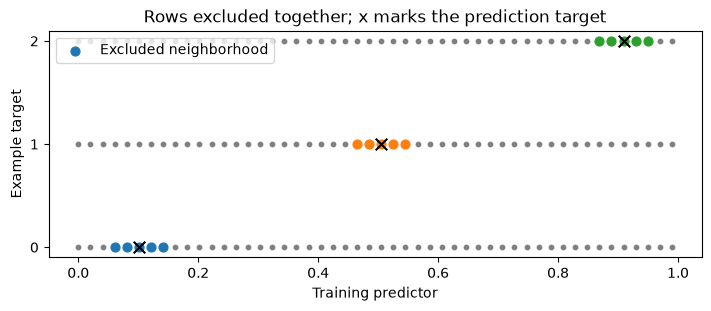

In [2]:
x=np.linspace(0,1,100)
data=pd.DataFrame({"x":x,"y":np.sin(4*np.pi*x)+rng.normal(0,.15,len(x))})
# Reserve alternating rows as an independent final test set.
train=data.iloc[::2].reset_index(drop=True)
test=data.iloc[1::2].copy()
n=len(train)
excluded=[np.arange(max(0,i-2),min(n,i+3))+1 for i in range(n)]
nei={"a":np.concatenate(excluded),"ma":np.cumsum([len(a) for a in excluded]),"d":np.arange(1,n+1),"md":np.arange(1,n+1)}
figure,axis=plt.subplots(figsize=(7,3),constrained_layout=True)
for row,target in enumerate([5,25,45]):
    axis.scatter(train.x,np.full(n,row),s=10,color="grey")
    axis.scatter(train.x.iloc[excluded[target]-1],np.full(len(excluded[target]),row),s=40,label="Excluded neighborhood" if row==0 else None)
    axis.scatter(train.x.iloc[target],row,marker="x",color="black",s=70)
axis.set(xlabel="Training predictor",ylabel="Example target",yticks=[0,1,2],title="Rows excluded together; x marks the prediction target")
axis.legend()
plt.show()
plt.close(figure)

## Compare fitted smooths on untouched rows

The neighborhood criterion selects smoothness using only training rows. The alternating test responses are generated with independent noise and remain outside both criteria; this split is not a claim about forecasting correlated time series.

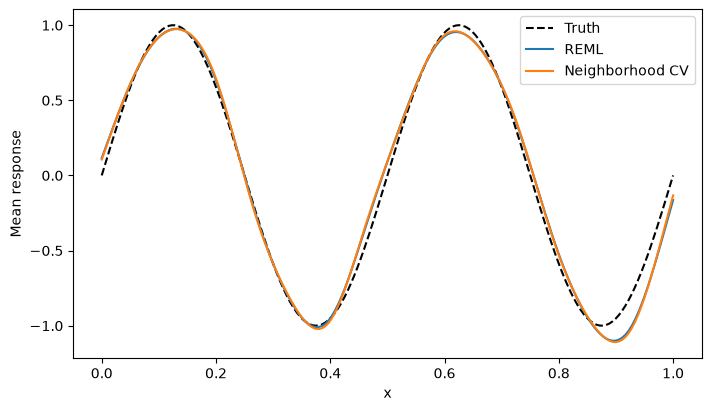

Model,Test RMSE
REML,0.159
Neighborhood CV,0.161


In [3]:
models={name:GAM(formula="y ~ s(x,bs='cr',k=16)",smoothing_method=method,optimize_smoothing=True,**options).fit(train) for name,method,options in [("REML","reml",{}),("Neighborhood CV","ncv",{"nei":nei})]}
grid=pd.DataFrame({"x":np.linspace(0,1,180)})
figure,axis=plt.subplots(figsize=(7,4),constrained_layout=True)
axis.plot(grid.x,np.sin(4*np.pi*grid.x),"k--",label="Truth")
for name,model in models.items():axis.plot(grid.x,model.predict(grid),label=name)
axis.set(xlabel="x",ylabel="Mean response")
axis.legend()
plt.show()
plt.close(figure)
pd.DataFrame([{"Model":name,"Test RMSE":mean_squared_error(test.y,m.predict(test))**.5} for name,m in models.items()]).style.hide(axis="index").format({"Test RMSE":"{:.3f}"})

The held-out errors are close: RMSE 0.159 for REML and 0.161 for neighborhood CV. The example demonstrates explicit exclusion semantics, rather than a guaranteed gain from that criterion.